# Шаблон цикла обучения нейросети

In [1]:
import pandas as pd
import torch
import torch.nn as nn
import numpy as np
import random
from torch.utils.data import Dataset, Subset, random_split, DataLoader
import matplotlib.pyplot as plt


In [2]:
data_path = 'https://code.s3.yandex.net/datasets/dataset_s26t4l3_case_prepared.csv'

RADNOM_SEED = 42
torch.manual_seed(RADNOM_SEED)
random.seed(RADNOM_SEED)
np.random.seed(RADNOM_SEED)

## 1. Создание модели

In [3]:
class SimpleNet(nn.Module):
    """Простейшая модель нейросети"""

    def __init__(self, input_dim: int, output_dim: int, hidden_dim: int = 16):
        super().__init__()

        self.fc1 = nn.Linear(in_features=input_dim, out_features=hidden_dim)

        self.relu = nn.ReLU()

        self.fc2 = nn.Linear(in_features=hidden_dim, out_features=output_dim)


    def forward(self, x):

        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

    

In [4]:
# задание размерностей нейросети
input_dim = 10  # число признаков
output_dim = 1 # бинарная классификация


In [5]:
# Инициализация модели
model = SimpleNet(input_dim=input_dim, output_dim=output_dim)

In [6]:
# Функция потерь и оптимизатор
loss_fn = nn.BCEWithLogitsLoss()  # объединяет в себе функцию активации Sigmoid и бинарную кросс-энтропию (BCELoss) в одном вычислительном шаге
optimizer = torch.optim.Adam(params=model.parameters(), lr=0.001)


## 2. Подготовка данных

In [7]:
df = pd.read_csv(data_path)
display(df.head(), df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10400 entries, 0 to 10399
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   viewer_feature_0  10000 non-null  float64
 1   viewer_feature_1  10390 non-null  float64
 2   viewer_feature_2  10390 non-null  float64
 3   viewer_feature_3  10390 non-null  float64
 4   viewer_feature_4  10390 non-null  float64
 5   viewer_feature_5  10390 non-null  float64
 6   viewer_feature_6  10390 non-null  float64
 7   viewer_feature_7  10390 non-null  float64
 8   viewer_feature_8  10390 non-null  float64
 9   viewer_feature_9  10390 non-null  float64
 10  target            10390 non-null  float64
dtypes: float64(11)
memory usage: 893.9 KB


,viewer_feature_0,viewer_feature_1,viewer_feature_2,viewer_feature_3,viewer_feature_4,viewer_feature_5,viewer_feature_6,viewer_feature_7,viewer_feature_8,viewer_feature_9,target
0,0.679479,0.443426,0.680090,0.707572,0.311562,0.369303,0.515954,0.399178,0.658842,0.314013,0.0
1,0.660695,0.417732,0.562167,0.921903,0.440935,0.452565,0.594774,0.349418,0.610861,0.649921,0.0
2,0.674402,0.436405,0.332139,0.528172,0.861070,0.471072,0.683915,0.501279,0.367233,0.308558,1.0
3,0.664770,0.423240,0.560319,0.914103,0.488316,0.694889,0.597315,0.299039,0.562690,0.653034,0.0
4,0.453053,0.184762,0.353021,0.578456,0.871245,0.690138,0.584438,0.741517,0.673144,0.474802,1.0


None

In [8]:
# заполнение пропусков
df = df.fillna(0)

In [9]:
class TableDataset(Dataset):
    """Загрузчик табличных данных"""

    def __init__(self, dataframe: pd.DataFrame):
        data_X = dataframe.drop(columns = 'target')
        data_y = dataframe['target']
        self.X = torch.tensor(data_X.to_numpy(dtype="float32"), dtype=torch.float32)
        self.y = torch.tensor(data_y.to_numpy(), dtype=torch.float32).unsqueeze(1)

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx: int):
        return self.X[idx], self.y[idx]
    

In [10]:
dataset = TableDataset(df)

In [11]:
# разбивка на train, val, test
total_size = len(dataset)
train_size = int(0.7 * total_size)
val_size = int(0.2 * total_size)
test_size = total_size - train_size - val_size

# подвыборки
train_dataset, val_dataset, test_dataset = random_split(
    dataset, [train_size, val_size, test_size]
)

# загрузчики данных
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False)

## 3. Цикл обучения

In [12]:
def training_loop(model, train_loader, optimizer, loss_fn) -> float:
    """Цикл обучения в рамках одной эпохи"""
    model.train()  # режим обучения
    train_loss = 0.

    for x_batch, y_batch in train_loader:
        optimizer.zero_grad()

        predictions = model(x_batch)
        loss = loss_fn(predictions, y_batch)
        loss.backward()

        optimizer.step()
        train_loss += loss.item() * x_batch.size(0)
        print(f" - Loss на батче: {loss.item()}")
    
    avg_train_loss = train_loss / len(train_loader.dataset)
    print(f"Loss на обучающей выборке: {avg_train_loss}") 
    return avg_train_loss

In [13]:
def validation_loop(model, val_loader, loss_fn) -> float:
    """Цикл валидации"""
    model.eval()  
    val_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():  
        for x_batch, y_batch in val_loader:
            predictions = model(x_batch)
            loss = loss_fn(predictions, y_batch)
            val_loss += loss.item() * x_batch.size(0)  # Накапливаем loss

            # Считаем значения для accuracy
            preds = torch.sigmoid(predictions) > 0.5
            correct += (preds == y_batch.bool()).sum().item()
            total += y_batch.size(0)

    # Средний loss и accuracy за эпоху
    avg_val_loss = val_loss / len(val_loader.dataset)
    val_acc = correct / total

    print(f"Loss на валидационной выборке: {avg_val_loss}")
    print(f"Accuracy на валидационной выборке: {val_acc}")

    return avg_val_loss


In [14]:
num_epochs = 10
epoch_train_loss = []
epoch_val_loss = []
best_val_loss = float('inf')  # для сохранения модели с лучшим лоссом на валидации

In [15]:
for epoch in range(num_epochs):
    print(f'Эпоха обучения: {epoch}')

    # цикл обучения
    avg_train_loss = training_loop(
        model, train_loader, optimizer, loss_fn
    )

    epoch_train_loss.append(avg_train_loss)

    # цикл валидации
    avg_val_loss = validation_loop(model, val_loader, loss_fn)

    epoch_val_loss.append(avg_val_loss)

    # чекпойнт для лучшей модели
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        # Сохраняем веса модели
        torch.save(model.state_dict(), 'best_model.pth')
        print(f'Эпоха {epoch+1}: Найден новый лучший чекпоинт, модель сохранена!') 

Эпоха обучения: 0
 - Loss на батче: 0.6825195550918579
 - Loss на батче: 0.6729128360748291
 - Loss на батче: 0.6572185754776001
 - Loss на батче: 0.6682827472686768
 - Loss на батче: 0.6791092753410339
 - Loss на батче: 0.6783487796783447
 - Loss на батче: 0.6486836075782776
 - Loss на батче: 0.6757807731628418
 - Loss на батче: 0.6540154218673706
 - Loss на батче: 0.6359365582466125
 - Loss на батче: 0.6511498093605042
 - Loss на батче: 0.6812880635261536
 - Loss на батче: 0.6379114389419556
 - Loss на батче: 0.6626235246658325
 - Loss на батче: 0.6500644683837891
 - Loss на батче: 0.6349716186523438
 - Loss на батче: 0.6638572812080383
 - Loss на батче: 0.6484339237213135
 - Loss на батче: 0.6367412209510803
 - Loss на батче: 0.7135928869247437
 - Loss на батче: 0.6799969673156738
 - Loss на батче: 0.6254466772079468
 - Loss на батче: 0.6427508592605591
 - Loss на батче: 0.6882121562957764
 - Loss на батче: 0.6422696709632874
 - Loss на батче: 0.6718158721923828
 - Loss на батче: 0.

## 4. Визуализация

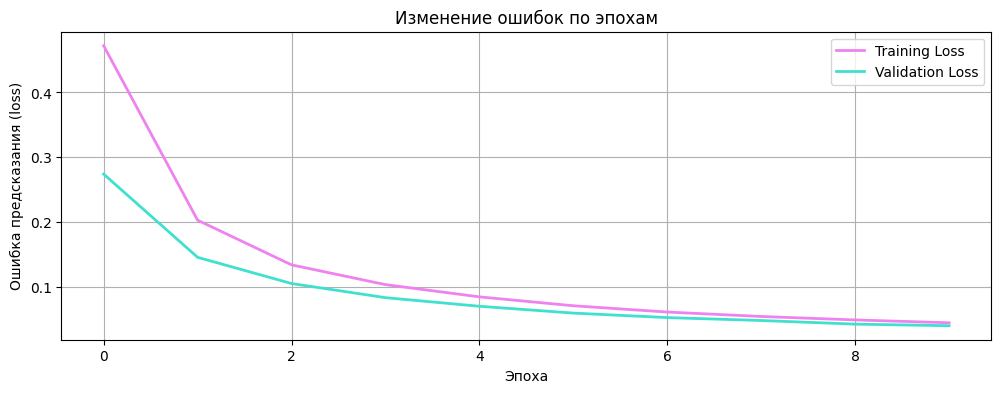

In [16]:
plt.figure(figsize=(12, 4))
plt.plot(epoch_train_loss, label="Training Loss", linewidth=2, color='violet')
plt.plot(epoch_val_loss, label="Validation Loss", linewidth=2, color='turquoise')
plt.xlabel("Эпоха")
plt.ylabel("Ошибка предсказания (loss)")
plt.title("Изменение ошибок по эпохам")
plt.legend()
plt.grid(True)
plt.show() 